In [215]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid
from numba import njit, prange
from numba_progress import ProgressBar
from scipy.stats import binned_statistic, binned_statistic_2d
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
plt.rcParams['figure.dpi'] = 300

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 1

In [3]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [4]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    x = np.concatenate(([0], x, xh + x[-1]))
    F = np.concatenate(([0], F, Fh))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

# Simulate Trajectories

In [5]:
def sim(C, ru0, xu, v=0.2, dt=1e-2):
    t = 0
    ft = [C(t*v)]
    while True:
        assert v*t < C.domain.max(), "Force left Chebychev domain"
        pu = np.clip(dt * ru0 * np.exp(C(v*t)*xu), 0, 1)
        if pu > np.random.rand(1):
            break
        ft.append(C(v*t))
        t += dt

    return np.array(ft)

Text(0, 0.5, 'F')

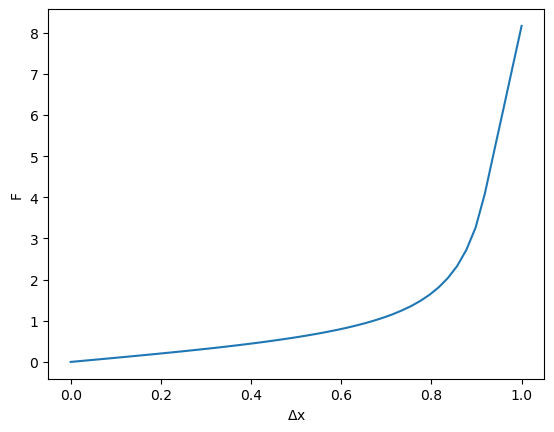

In [6]:
C, _, _ = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")

# Simulate Trajectories

In [7]:
class EndOfCache(Exception):
    "End of cache reached, some bonds did not break"
    pass

class ExceededLUT(Exception):
    "End of force LUT reached"
    pass

@njit(parallel=True)
def nb_trajectories(ruxu, v, lut_x, lut_F, dt, cache_length=20000):
    N = ruxu.shape[0]

    lut_size = lut_x.shape[0]
    lut_maxx = lut_x[-1]

    force = np.full((cache_length, N), np.nan) # The force at each time step

    # Generate full feature vectors for all data points
    # I do this just out of laziness, these could all be prepared
    # efficiently later before the training.
    
    time  = np.full((cache_length, N), np.nan) # Time at each step
    pos   = np.full((cache_length, N), np.nan) # Position at each time step
    v_t   = np.full((cache_length, N), np.nan) # Velocity at each time step
    bound = np.full(N, True) # Keeping track if the bond is active
    event = np.zeros(N) # Index of when the unbinding even occurs
    
    t = 0 # Time index
    force[t, :] = 0

    bonds_left = True

    while bonds_left == True:

        t+=1
        
        for sample in prange(N):
            
            ru = ruxu[sample, 0]
            xu = ruxu[sample, 1]
            
            if bound[sample]:
                x = v[sample] * t * dt
                if x >= lut_maxx:
                    x = lut_maxx
                    #raise ExceededLUT
                idx = lut_size * x / lut_maxx
                f = lut_F[int(idx)]
                force[t, sample] = f
                time[t, sample] = t
                pos[t, sample] = x
                v_t[t, sample] = v[sample]
                
                pu = min(dt * ru * np.exp(f*xu), 1)
                a  = np.random.rand()

                if pu > a:
                    bound[sample] = False
                    event[sample] = t

        bonds_left = np.any(bound)
        if t == cache_length:
            raise EndOfCache
            break

    end_of_sim = int(np.max(event))
    force = force[:end_of_sim+1, :]
    time = time[:end_of_sim+1, :]
    pos = pos[:end_of_sim+1, :]
    v_t = v_t[:end_of_sim+1, :]

    return force, event, time, pos, v_t


In [301]:
scores = []
ru0_GT = 0.05
xu_GT  = 0.2
dt = 1e-2

x = np.linspace(0, 5, 10000)
F = C(x)
force_lut = (x, F)

# Test data
N_trajectories = 1000
ruxu_data_test = np.array([ru0_GT, xu_GT])[np.newaxis,:].repeat(N_trajectories, axis=0)
v_test = np.random.uniform(0.01, 0.4, size=N_trajectories)
FORCE_test, EVENT_test, TIME_test, POS_test, V_test = nb_trajectories(ruxu_data_test, v_test, x, F, dt=dt)
NNX_test = np.stack([FORCE_test.flatten('F'),
                V_test.flatten('F'),
                TIME_test.flatten('F'),
                POS_test.flatten('F'),
               ]).T

idx = ~np.isnan(NNX_test).any(axis=1)
NNX_test = NNX_test[idx, :]
X_test = NNX_test[:, 1:]
y_test = NNX_test[:, 0] 

# Training data
N_trajectories = 30
N_trajectories_train = N_trajectories
ruxu_data = np.array([ru0_GT, xu_GT])[np.newaxis,:].repeat(N_trajectories, axis=0)
v = np.random.uniform(0.01, 0.4, size=N_trajectories)
v = np.linspace(0.01, 0.4, N_trajectories)
FORCE, EVENT, TIME, POS, V = nb_trajectories(ruxu_data, v, x, F, dt=dt)
NNX = np.stack([FORCE.flatten('F'),
                V.flatten('F'),
                TIME.flatten('F'),
                POS.flatten('F'),
               ]).T

idx = ~np.isnan(NNX).any(axis=1)
NNX = NNX[idx, :]
X_train = NNX[:, 1:]
y_train = NNX[:, 0] 


pipe = Pipeline(steps=[("scaler", StandardScaler()), ("net", MLPRegressor())])

print("Start training")
pipe.set_params(net__max_iter=500)
pipe.set_params(net__alpha=1e-4)
pipe.set_params(net__hidden_layer_sizes=(100,))
pipe.set_params(net__activation='tanh')
pipe.fit(X_train, y_train)
print("Scoring...")
score = pipe.score(X_test, y_test)
print(score)

Start training
Scoring...
0.9977108388950927


In [302]:
fT = X_test[:, 1]
fV = X_test[:, 0]
fT_train = X_train[:, 1]
fV_train = X_train[:, 0]

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_20809/3445834084.py:3: RuntimeWarning: invalid value encountered in log
  plt.imshow(np.log(stat.statistic).T, origin='lower', extent=extent, aspect='auto')


Text(0, 0.5, 'v')

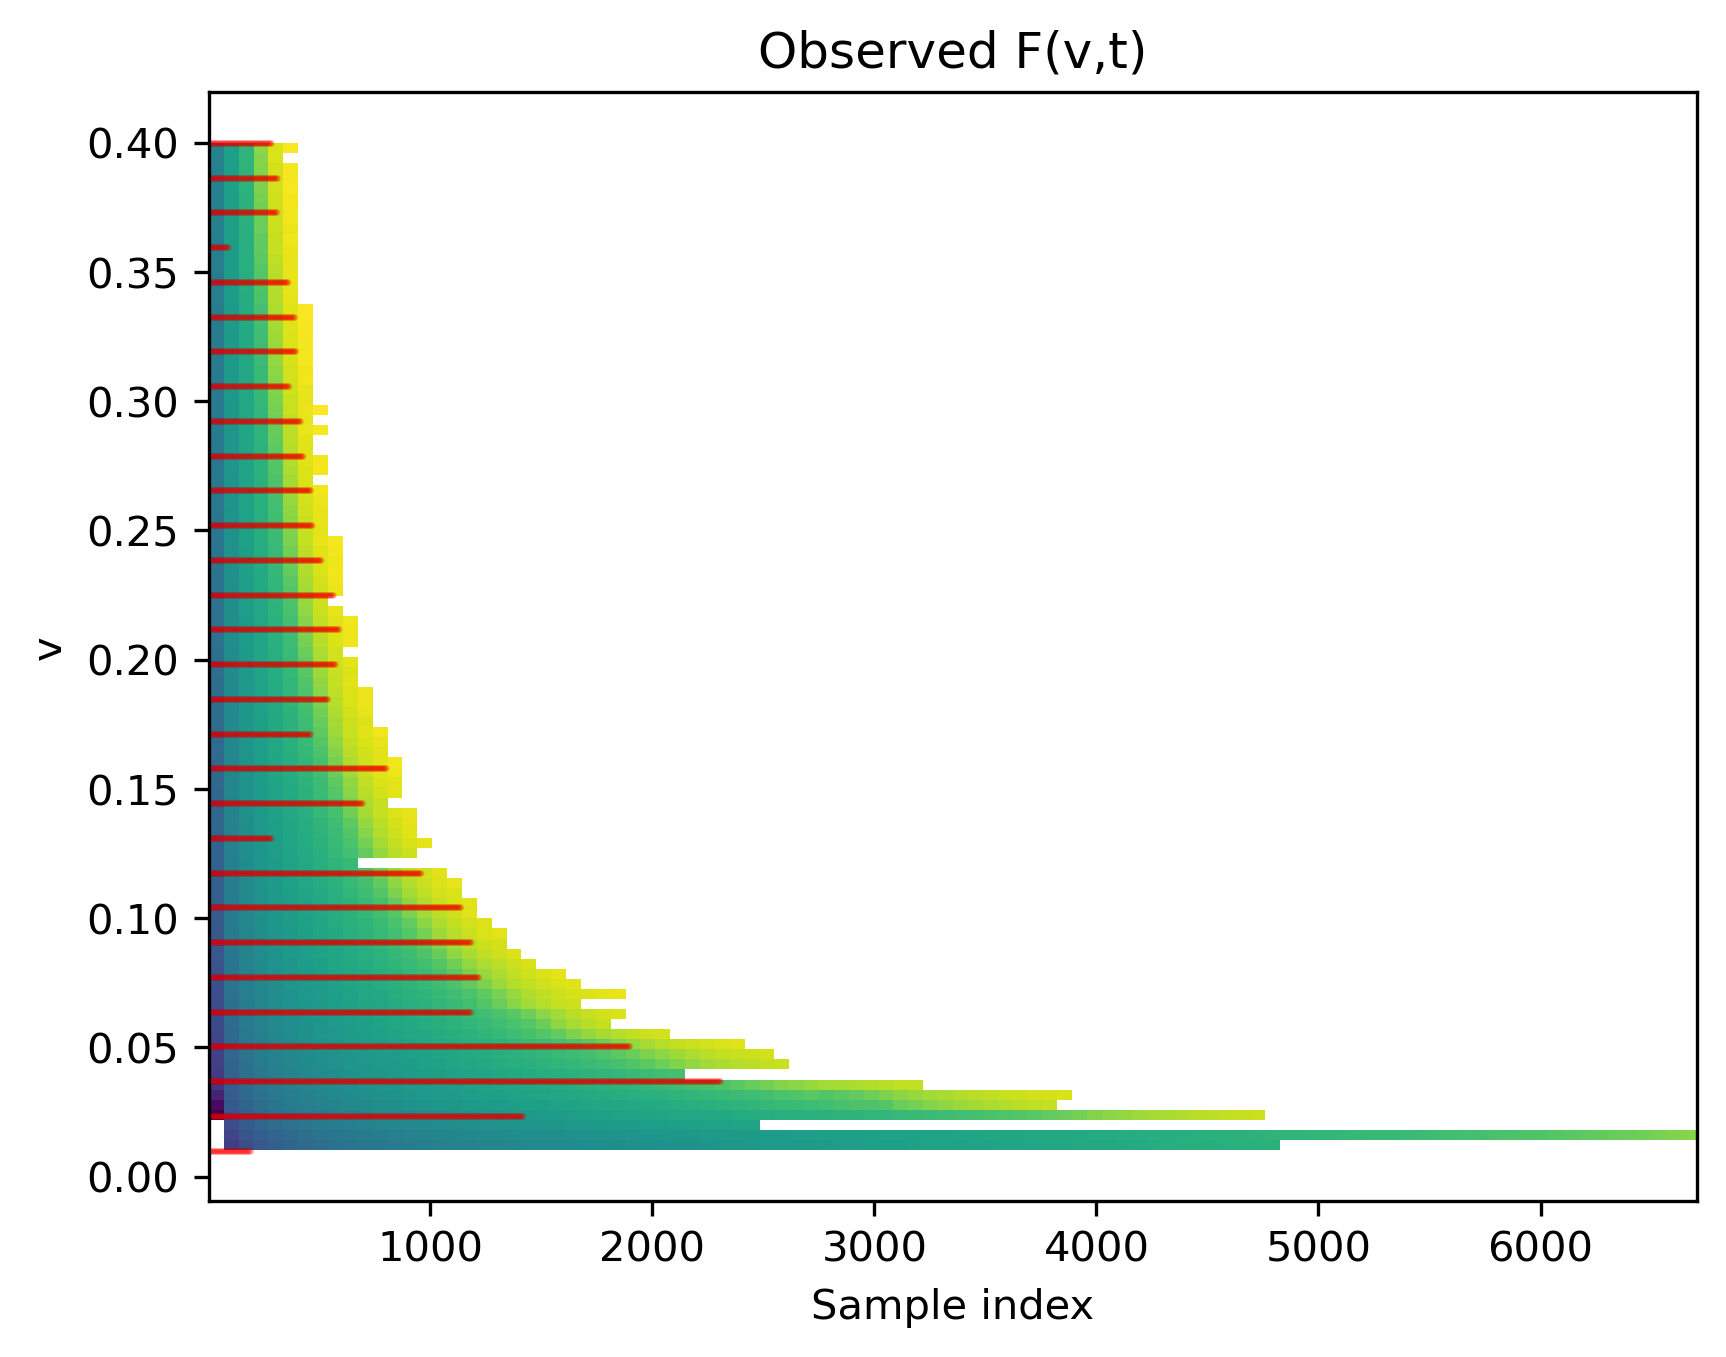

In [303]:
extent = [fT.min(), fT.max(), fV.min(), fV.max()]
stat = binned_statistic_2d(fT, fV, y_test, bins=100)
plt.imshow(np.log(stat.statistic).T, origin='lower', extent=extent, aspect='auto')
plt.title("Observed F(v,t)")
plt.plot(fT_train, fV_train, '.r', markersize=1, alpha=0.05)
plt.xlabel("Sample index")
plt.ylabel("v")

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_20809/1075988308.py:3: RuntimeWarning: invalid value encountered in log
  plt.imshow(np.log(stat.statistic).T, origin='lower', extent=extent, aspect='auto')


Text(0, 0.5, 'v')

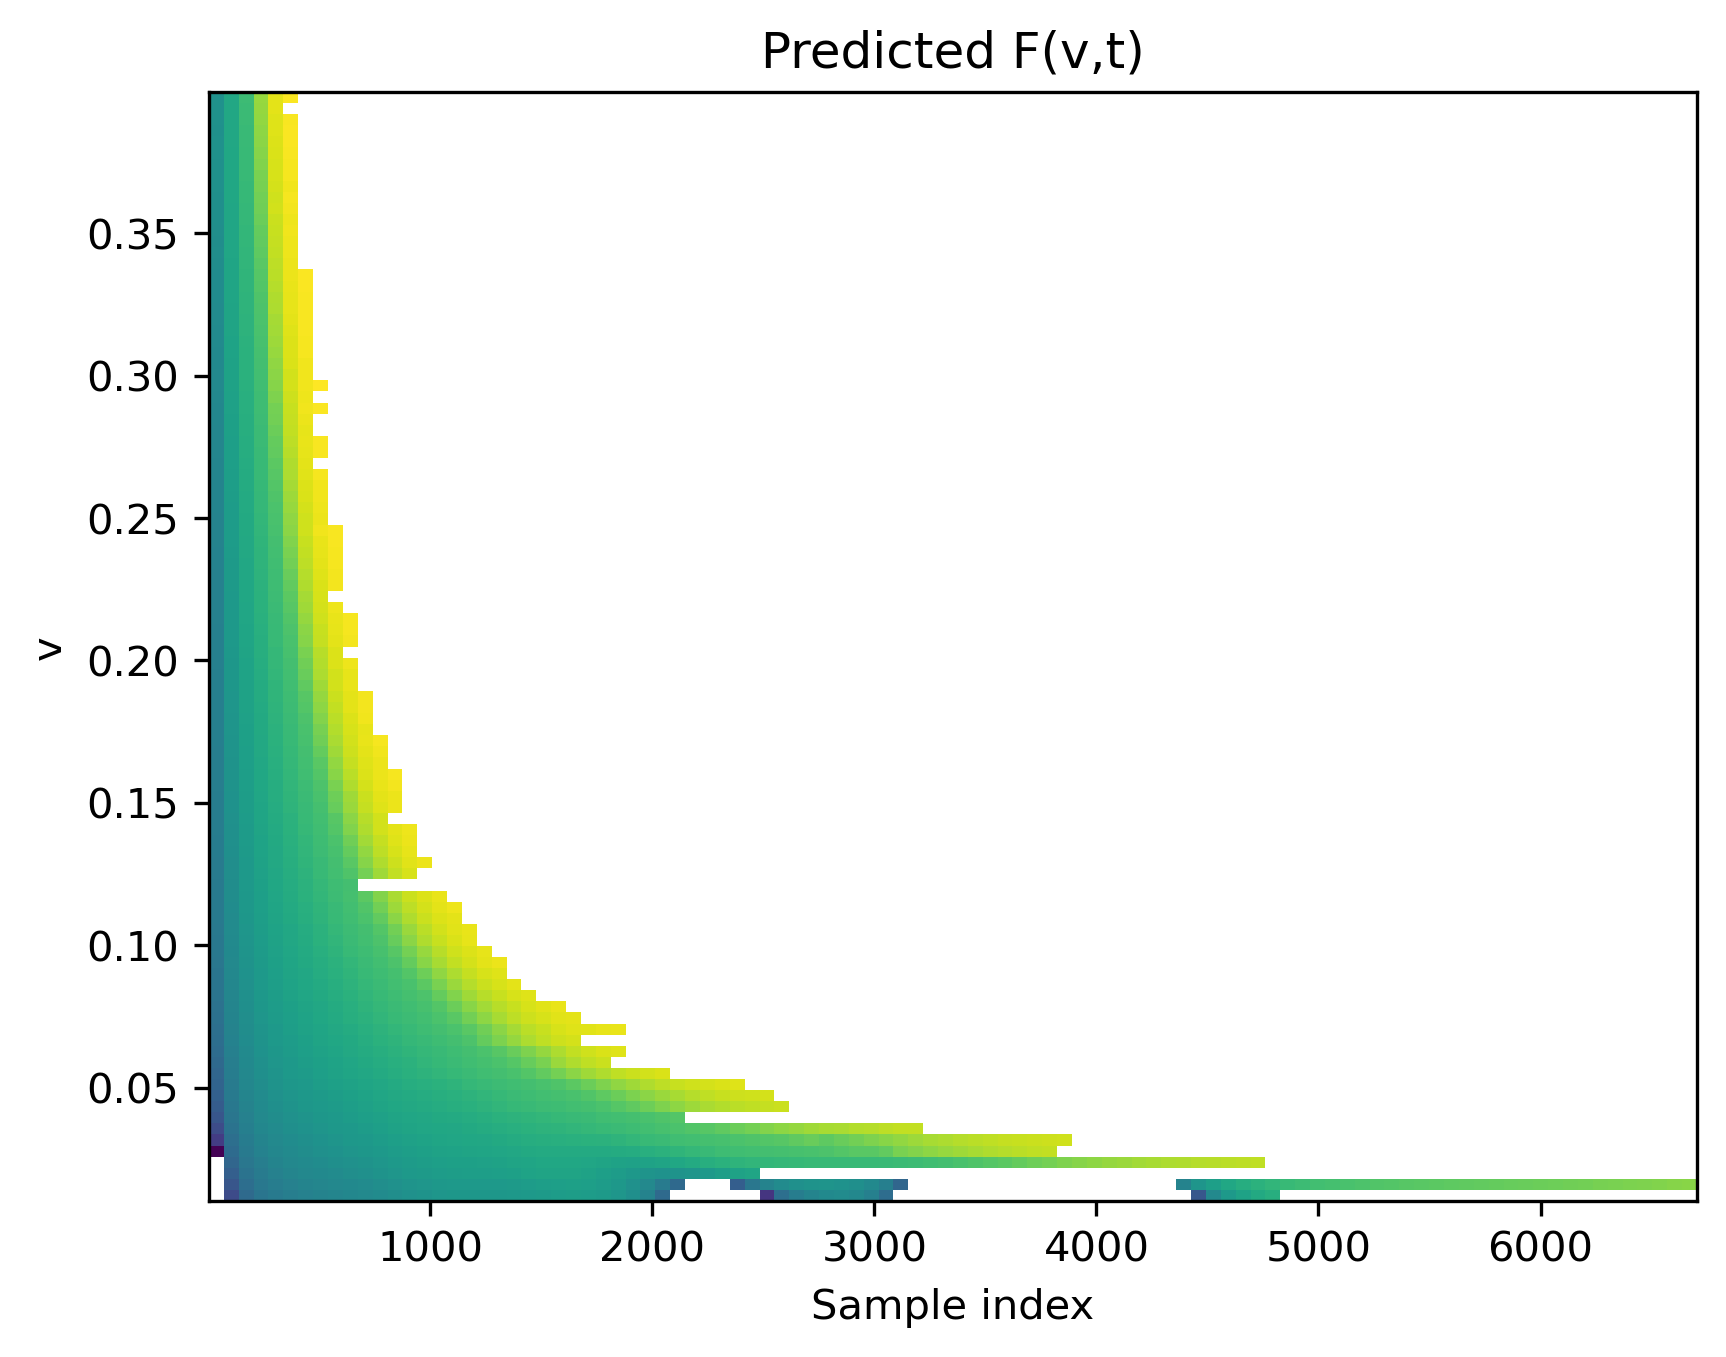

In [304]:
Y_pred = pipe.predict(X_test)
stat = binned_statistic_2d(fT, fV, Y_pred.flatten(), bins=100)
plt.imshow(np.log(stat.statistic).T, origin='lower', extent=extent, aspect='auto')
plt.title("Predicted F(v,t)")
plt.xlabel("Sample index")
plt.ylabel("v")

/var/folders/b6/mywb7pxx19q_hkpvp9ctcv4c0000gn/T/ipykernel_20809/252359432.py:2: RuntimeWarning: invalid value encountered in log
  plt.imshow(np.log(stat.statistic), origin='lower')


Text(0, 0.5, 'v')

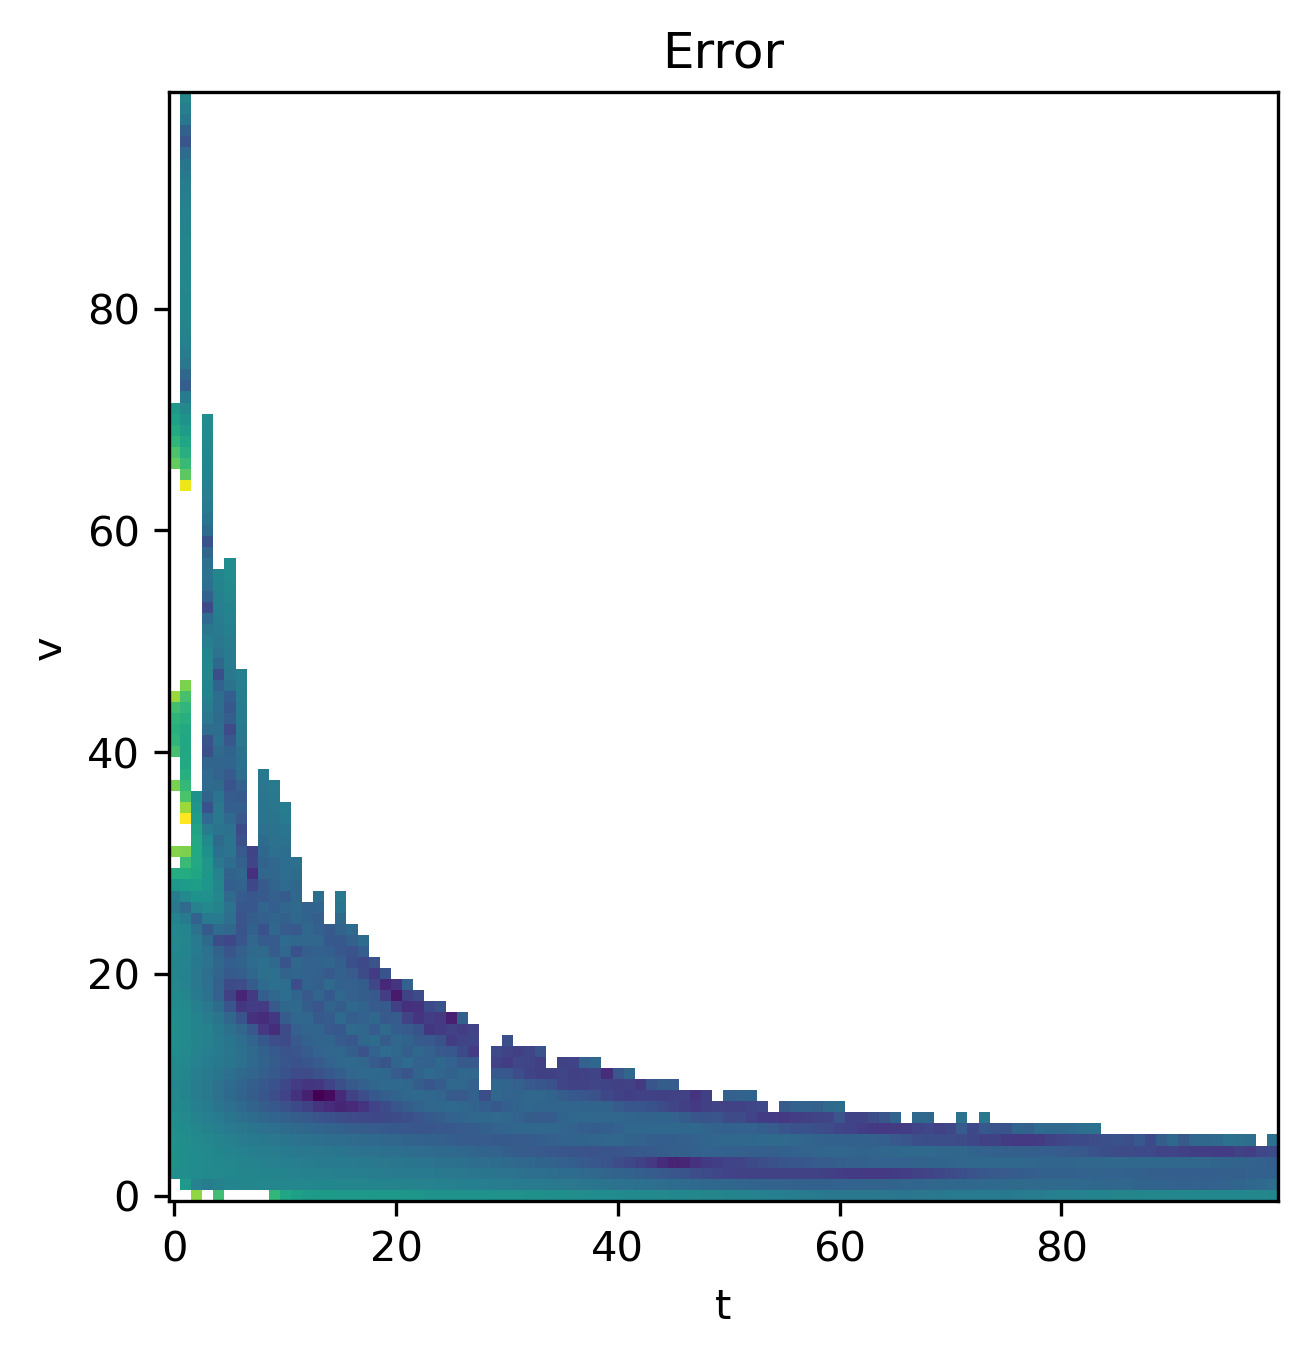

In [305]:
stat = binned_statistic_2d(fT, fV, np.abs(y_test - Y_pred.flatten())/Y_pred, bins=100)
plt.imshow(np.log(stat.statistic), origin='lower')
plt.title("Error")
plt.xlabel("t")
plt.ylabel("v")